# Alphabet (GOOGL): Monte Carlo of the DCF Value

Companion to slide 30 of my Alphabet deep dive (`alphabet-deep-dive-oct2026.pdf`) ("Monte Carlo: Values Center on \$201 Under My Assumptions").

**Personal hobby project. For informational and educational purposes only, not investment advice. Model outputs are assumption-dependent. Use at your own risk.**

The deck values Alphabet with a three-scenario DCF in `alphabet-model-oct2026.xlsx`. A scenario moves every input in the same direction at once, so it describes the edges of the range rather than how likely each outcome is. This notebook draws the uncertain inputs jointly, 10,000 times, and runs each draw through the same valuation.

**How it works**
1. Load the model through `engine/engine.py`, a replica of the workbook's operating model and DCF, and check it against the workbook's own results.
2. Draw ten inputs from stated distributions. Three of them (return on new capital, Cloud revenue per capex dollar, margin path) share a common "AI payoff" factor, so a good draw for one tends to be a good draw for the others.
3. Value each draw at the October 16, 2026 price date, as the deck does.
4. Read off the distribution: percentiles, the chance of exceeding the price, and which inputs move the answer.

The input distributions are my judgments, centred on the base case. The result describes uncertainty in the inputs around that base case; it is not a forecast of where the stock will trade.

**To run:** open this notebook from the repository's top folder, next to the workbook. It needs `numpy`, `pandas`, `matplotlib` and `openpyxl`, and it imports the engine from `engine/`. A full run takes a minute or two.

In [1]:
import copy
import math
import pathlib
import random
import sys

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import openpyxl
import pandas as pd

ROOT = pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'engine'))
import engine                                    # replica of the workbook DCF
from scenarios_lib import tweak_factory          # input overrides, as used for the deck

WORKBOOK = ROOT / 'alphabet-model-oct2026.xlsx'

# Brand palette (CHART-COLORS.md)
BLUE_DEEP  = '#02223c'
BLUE_MAIN  = '#005a96'
BLUE_SOFT  = '#0f80c4'
BLUE_LIGHT = '#8fd1ff'
BLUE_MUTED = '#d8e7f5'
TITLE_BLUE = '#13597B'
TEXT_MAIN  = '#0f172a'
TEXT_MUTED = '#4b5563'
RED_SOFT   = '#dc2626'   # data contrast only: above the price, negative effects

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Garamond', 'Georgia', 'Times New Roman', 'serif'],
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': False,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': TEXT_MUTED,
    'axes.labelcolor': TEXT_MUTED,
    'xtick.color': TEXT_MAIN,
    'ytick.color': TEXT_MAIN,
    'text.color': TEXT_MAIN,
    'figure.dpi': 110,
    'savefig.dpi': 180,
})


def source(fig, text):
    fig.text(0.99, 0.01, text, ha='right', va='bottom', fontsize=8, color=TEXT_MUTED)


dollars = mticker.FuncFormatter(lambda v, _: f'${v:,.0f}')
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

## 1. Load the model and check it against the workbook

The engine rebuilds all three scenarios from the workbook's inputs. Before drawing anything, its price-date values are compared with the workbook's own results on `11 Valuation` row 90. They should agree to the cent.

In [2]:
cases, _ = engine.load(str(WORKBOOK))
BASE = cases['Base']
PRICE = BASE['price']
tweak = tweak_factory(BASE)

base_run = engine.value(BASE)
KE = base_run['ke']                      # cost of equity
DIVIDENDS = 0.88                         # next twelve months, 11 Valuation C92
TARGET = base_run['pdv'] * (1 + KE) - DIVIDENDS

wb = openpyxl.load_workbook(WORKBOOK, data_only=True, read_only=True)
row90 = [c.value for c in wb['11 Valuation']['C90:E90'][0]]
wb.close()

check = pd.DataFrame({
    'Engine': [engine.value(cases[n])['pdv'] for n in ('Base', 'Best', 'Worst')],
    'Workbook (11 Valuation row 90)': row90,
}, index=['Base', 'Best', 'Worst'])
check['Difference'] = check['Engine'] - check['Workbook (11 Valuation row 90)']
print(f'Price ${PRICE:.2f} (Oct 16, 2026 close); cost of equity {KE:.2%}; twelve-month model value ${TARGET:.2f}')
check

Price $340.59 (Oct 16, 2026 close); cost of equity 9.73%; twelve-month model value $221.46


,Engine,Workbook (11 Valuation row 90),Difference
Base,202.63,202.63,0.00
Best,365.07,365.07,-0.00
Worst,80.57,80.57,0.00


## 2. The inputs and how they are drawn

Ten inputs vary. Each distribution is centred on the base case, with a range set to bracket the input's own history and what peers earn.

| Input | Base case | Distribution |
|---|---|---|
| Return on new capital after FY2030E | 15% | Lognormal, 5th to 95th percentile about 9% to 25%, capped at 7% and 40% |
| Cloud revenue per dollar of prior-year capex | 30 cents | Normal, sd 4 cents, capped at 15 and 50 cents |
| Pre-ramp margin expansion a year | 0.5pp | Normal, sd 0.5pp, capped at -1pp and +2pp |
| Search, YouTube and Subscriptions growth | base path | Shift drawn from a normal, sd 1.5pp a year |
| Capex intensity, FY2027E to FY2030E | base path | Shift drawn from a normal, sd 2pp |
| Short-lived share of assets not yet in service | 60% | Uniform, 45% to 80% |
| Beta | 1.08 | Normal, sd 0.10 |
| Equity risk premium | 4.42% | Normal, sd 0.4pp |
| Ten-year Treasury yield | 4.96% | Normal, sd 0.5pp |
| Terminal growth | 3.0% | Uniform, 2.5% to 3.5% |

The first three describe whether the AI build pays. They load 0.7 on one shared "AI payoff" draw, so they tend to move together; the rest are independent.

The seed is fixed (20261015), so every run gives the same 10,000 draws as the deck.

In [3]:
N = 10_000
random.seed(20261015)

draws, values = [], []
for _ in range(N):
    z_ai = random.gauss(0, 1)                                   # the shared AI-payoff factor
    mix = lambda: 0.7 * z_ai + math.sqrt(1 - 0.49) * random.gauss(0, 1)
    p = dict(
        ronic=min(0.40, max(0.07, 0.15 * math.exp(0.31 * mix()))),
        cents=min(0.50, max(0.15, 0.30 + 0.04 * mix())),
        step=min(0.02, max(-0.01, 0.005 + 0.005 * mix())),
        services=random.gauss(0, 0.015),
        capex_shift=random.gauss(0, 0.02),
        short=random.uniform(0.45, 0.80),
        beta=random.gauss(BASE['beta'], 0.10),
        erp=random.gauss(BASE['erp'], 0.004),
        rf=random.gauss(BASE['rf'], 0.005),
        g=random.uniform(0.025, 0.035),
    )
    draws.append(p)
    values.append(engine.value(tweak(**p))['pdv'])

mc = pd.DataFrame(draws)
mc['value'] = values
print(f'{len(mc):,} draws valued')

# what was actually drawn, in readable units
units = {
    'ronic': ('Return on new capital after FY2030E', lambda x: f'{x:.1%}'),
    'cents': ('Cloud revenue per capex dollar', lambda x: f'{x * 100:.1f} cents'),
    'step': ('Pre-ramp margin expansion a year', lambda x: f'{x * 100:+.2f}pp'),
    'services': ('Services growth shift', lambda x: f'{x * 100:+.2f}pp'),
    'capex_shift': ('Capex intensity shift', lambda x: f'{x * 100:+.2f}pp'),
    'short': ('Short-lived asset share', lambda x: f'{x:.0%}'),
    'beta': ('Beta', lambda x: f'{x:.2f}'),
    'erp': ('Equity risk premium', lambda x: f'{x:.2%}'),
    'rf': ('Ten-year Treasury yield', lambda x: f'{x:.2%}'),
    'g': ('Terminal growth', lambda x: f'{x:.2%}'),
}
pd.DataFrame({name: [fmt(mc[k].quantile(q)) for q in (0.05, 0.5, 0.95)] for k, (name, fmt) in units.items()},
             index=['5th percentile', 'Median', '95th percentile']).T

10,000 draws valued


,5th percentile,Median,95th percentile
Return on new capital after FY2030E,9.1%,15.0%,25.1%
Cloud revenue per capex dollar,23.4 cents,30.0 cents,36.6 cents
Pre-ramp margin expansion a year,-0.32pp,+0.49pp,+1.33pp
Services growth shift,-2.51pp,-0.05pp,+2.48pp
Capex intensity shift,-3.36pp,-0.02pp,+3.26pp
Short-lived asset share,47%,62%,78%
Beta,0.91,1.08,1.24
Equity risk premium,3.77%,4.42%,5.08%
Ten-year Treasury yield,4.15%,4.97%,5.79%
Terminal growth,2.55%,3.01%,3.45%


## 3. The distribution of value

The headline numbers on slide 30, recomputed here. The median sits just below the base case because the return on new capital is lognormal: its downside is bounded and its upside is long, so the mean is pulled above the median. In the histogram, the last bar holds every draw above \$485.

In [4]:
v = mc['value']
summary = pd.Series({
    '5th percentile': v.quantile(0.05),
    '25th percentile': v.quantile(0.25),
    'Median': v.median(),
    'Mean': v.mean(),
    '75th percentile': v.quantile(0.75),
    '95th percentile': v.quantile(0.95),
    'Base case (no uncertainty)': base_run['pdv'],
}, name='Value per share, $').to_frame()
p_above = (v > PRICE).mean()
p_below_target = (v < 221).mean()
print(f'Probability the value exceeds the ${PRICE:.2f} price: {p_above:.1%}')
print(f'Probability the value is below the $221 model value: {p_below_target:.1%}')
summary

Probability the value exceeds the $340.59 price: 3.4%
Probability the value is below the $221 model value: 63.3%


,"Value per share, $"
5th percentile,121.94
25th percentile,164.49
Median,201.05
Mean,208.49
75th percentile,243.58
95th percentile,321.63
Base case (no uncertainty),202.63


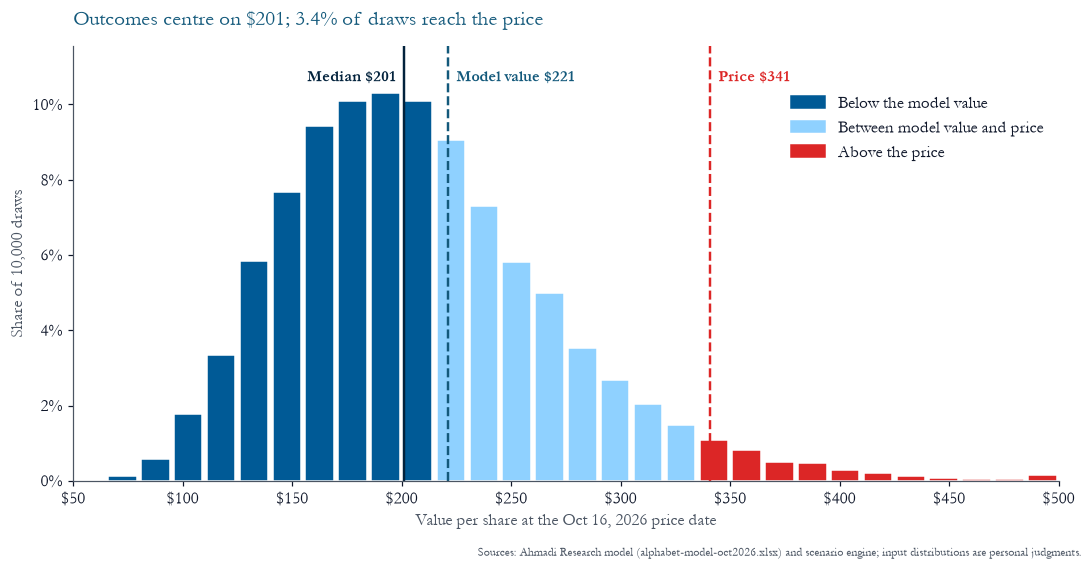

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.2))
edges = np.arange(50, 515, 15)
clipped = v.clip(upper=edges[-1] - 0.01)                      # last bin holds every draw above it
counts, _ = np.histogram(clipped, bins=edges)
share = counts / len(v) * 100
mids = (edges[:-1] + edges[1:]) / 2
colors = [BLUE_MAIN if m < 221 else (BLUE_LIGHT if m < PRICE else RED_SOFT) for m in mids]
ax.bar(mids, share, width=13, color=colors, edgecolor='white', linewidth=1)

for x, label, col, style, side in [(221, 'Model value $221', TITLE_BLUE, '--', 'right'),
                                   (v.median(), f'Median ${v.median():.0f}', BLUE_DEEP, '-', 'left'),
                                   (PRICE, f'Price ${PRICE:.0f}', RED_SOFT, '--', 'right')]:
    ax.axvline(x, color=col, linestyle=style, linewidth=1.6)
    ax.text(x + (4 if side == 'right' else -4), share.max() * 1.03, label, color=col, fontsize=10.5, weight='bold',
            ha='left' if side == 'right' else 'right')

ax.set_xlim(50, 500)
ax.set_ylim(0, share.max() * 1.12)
ax.xaxis.set_major_formatter(dollars)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel('Value per share at the Oct 16, 2026 price date')
ax.set_ylabel('Share of 10,000 draws')
ax.set_title(f'Outcomes centre on ${v.median():.0f}; {p_above:.1%} of draws reach the price',
             color=TITLE_BLUE, fontsize=14, loc='left', pad=14)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE_MAIN, BLUE_LIGHT, RED_SOFT)]
ax.legend(handles, ['Below the model value', 'Between model value and price', 'Above the price'],
          frameon=False, loc='upper right', bbox_to_anchor=(1, 0.92))
source(fig, 'Sources: Ahmadi Research model (alphabet-model-oct2026.xlsx) and scenario engine; input distributions are personal judgments.')
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 4. The same draws as a cumulative curve

Read any value on the horizontal axis and the curve gives the share of draws below it. The two marked points are the ones that matter for the model label.

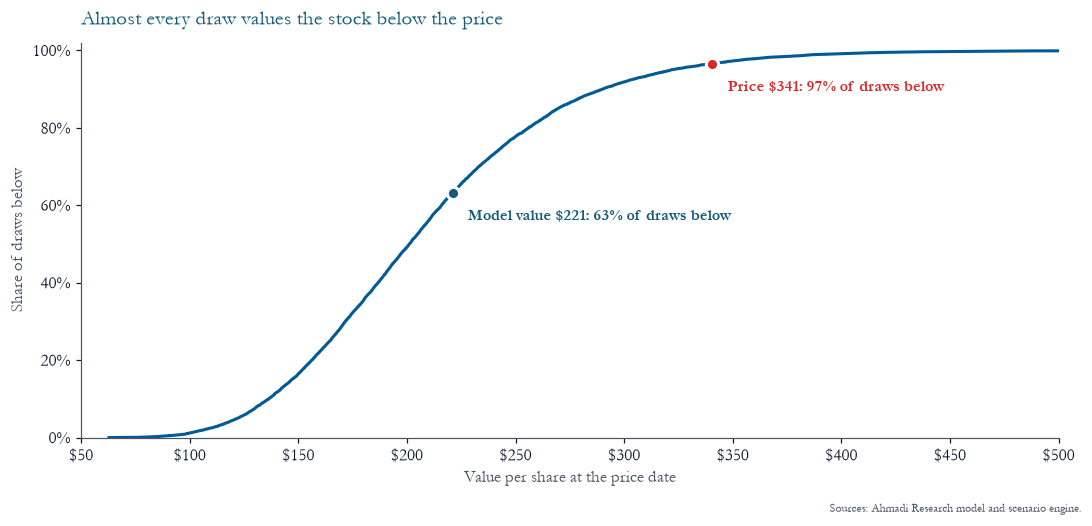

In [6]:
xs = np.sort(v.values)
ys = np.arange(1, len(xs) + 1) / len(xs)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(xs, ys, color=BLUE_MAIN, linewidth=2)
for x, label, col in [(221, 'Model value $221', TITLE_BLUE), (PRICE, f'Price ${PRICE:.0f}', RED_SOFT)]:
    y = (v < x).mean()
    ax.plot([x], [y], marker='o', markersize=8, color=col, markeredgecolor='white', markeredgewidth=2, zorder=3)
    ax.annotate(f'{label}: {y:.0%} of draws below', (x, y), xytext=(10, -18), textcoords='offset points',
                color=col, fontsize=10.5, weight='bold')
ax.set_xlim(50, 500)
ax.set_ylim(0, 1.02)
ax.xaxis.set_major_formatter(dollars)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.set_xlabel('Value per share at the price date')
ax.set_ylabel('Share of draws below')
ax.set_title('Almost every draw values the stock below the price', color=TITLE_BLUE, fontsize=14, loc='left', pad=12)
source(fig, 'Sources: Ahmadi Research model and scenario engine.')
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 5. Which inputs move the answer

The correlation between each input and the value shows direction and rough strength. A positive bar means a higher draw of that input raises the value. The three AI-build inputs look large partly because they move together through the shared factor.

This is a quick read, not a variance split. Slide 32 apportions the variance properly by rerunning the simulation with one group of inputs varying at a time; there the AI-build group explains about 72% of the variance and the discount-rate inputs about 22%.

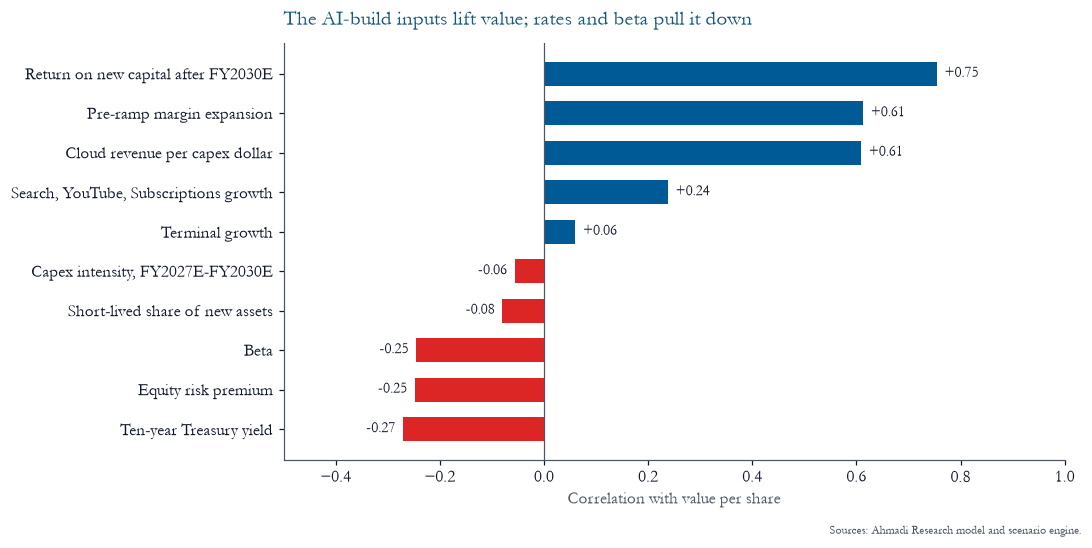

In [7]:
labels = {
    'ronic': 'Return on new capital after FY2030E',
    'cents': 'Cloud revenue per capex dollar',
    'step': 'Pre-ramp margin expansion',
    'services': 'Search, YouTube, Subscriptions growth',
    'capex_shift': 'Capex intensity, FY2027E-FY2030E',
    'short': 'Short-lived share of new assets',
    'beta': 'Beta',
    'erp': 'Equity risk premium',
    'rf': 'Ten-year Treasury yield',
    'g': 'Terminal growth',
}
corr = mc[list(labels)].corrwith(mc['value']).rename(index=labels).sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(corr.index, corr.values, color=[BLUE_MAIN if c > 0 else RED_SOFT for c in corr.values], height=0.6)
for i, c in enumerate(corr.values):
    ax.text(c + (0.015 if c > 0 else -0.015), i, f'{c:+.2f}', va='center', ha='left' if c > 0 else 'right',
            fontsize=10, color=TEXT_MAIN)
ax.axvline(0, color=TEXT_MUTED, linewidth=0.8)
ax.set_xlim(-0.5, 1)
ax.set_xlabel('Correlation with value per share')
ax.set_title('The AI-build inputs lift value; rates and beta pull it down',
             color=TITLE_BLUE, fontsize=14, loc='left', pad=12)
source(fig, 'Sources: Ahmadi Research model and scenario engine.')
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

The strongest single input, the return on new capital after FY2030E, plotted against the value it produces. Each dot is one draw; the vertical spread at any return comes from the other nine inputs.

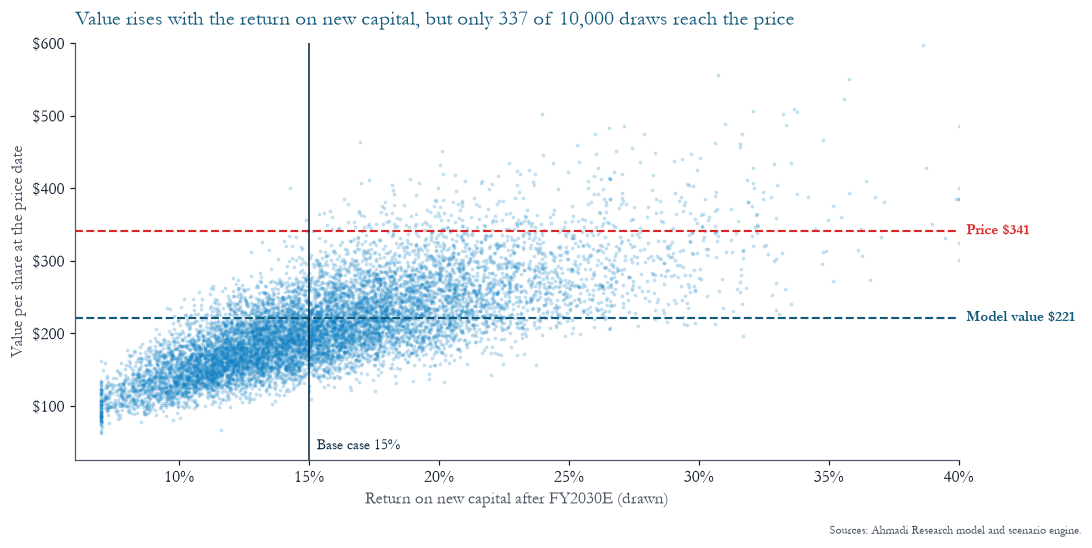

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(mc['ronic'] * 100, mc['value'], s=6, color=BLUE_SOFT, alpha=0.25, linewidths=0)
for y, label, col in [(PRICE, f'Price ${PRICE:.0f}', RED_SOFT), (221, 'Model value $221', TITLE_BLUE)]:
    ax.axhline(y, color=col, linestyle='--', linewidth=1.4)
    ax.text(40.3, y, label, color=col, fontsize=10, weight='bold', va='center')
ax.axvline(15, color=BLUE_DEEP, linewidth=1)
ax.text(15.3, 40, 'Base case 15%', color=BLUE_DEEP, fontsize=10)
ax.set_xlim(6, 40)
ax.set_ylim(25, 600)
ax.yaxis.set_major_formatter(dollars)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel('Return on new capital after FY2030E (drawn)')
ax.set_ylabel('Value per share at the price date')
above = mc[mc['value'] > PRICE]
ax.set_title(f'Value rises with the return on new capital, but only {len(above)} of 10,000 draws reach the price',
             color=TITLE_BLUE, fontsize=14, loc='left', pad=12)
source(fig, 'Sources: Ahmadi Research model and scenario engine.')
fig.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 6. Are 10,000 draws enough?

If the simulation has converged, the median and the chance of exceeding the price stop moving much as draws are added. The tail share converges more slowly than the median because only a few hundred draws land above the price.

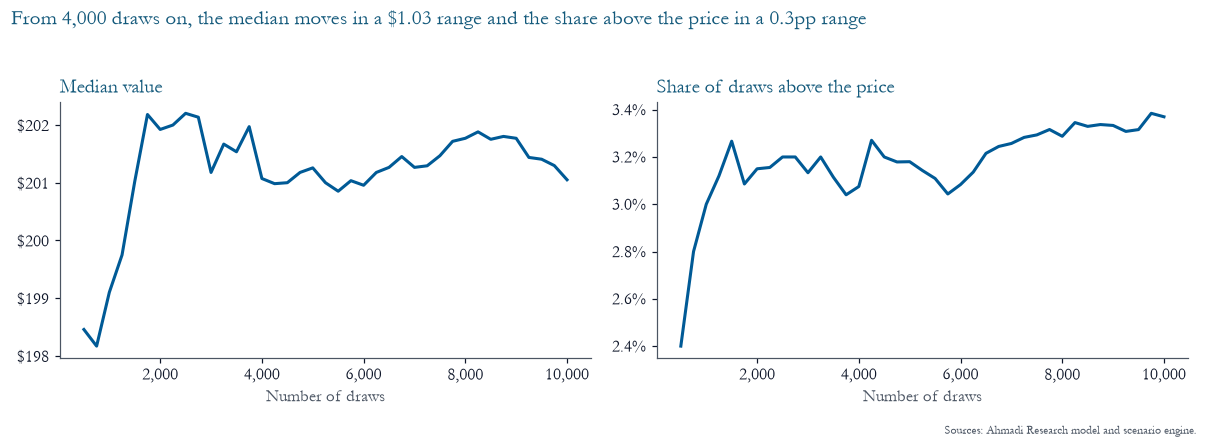

Median after 5,000 draws $201.26; after 10,000 $201.05


In [9]:
k = np.arange(500, N + 1, 250)
running_median = [np.median(v.values[:n]) for n in k]
running_above = [(v.values[:n] > PRICE).mean() * 100 for n in k]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k, running_median, color=BLUE_MAIN, linewidth=2)
axes[0].set_title('Median value', color=TITLE_BLUE, loc='left')
axes[0].yaxis.set_major_formatter(dollars)
axes[1].plot(k, running_above, color=BLUE_MAIN, linewidth=2)
axes[1].set_title('Share of draws above the price', color=TITLE_BLUE, loc='left')
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter(decimals=1))
for a in axes:
    a.set_xlabel('Number of draws')
    a.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
late = k >= 4000
fig.suptitle(f'From 4,000 draws on, the median moves in a ${np.ptp(np.array(running_median)[late]):.2f} range '
             f'and the share above the price in a {np.ptp(np.array(running_above)[late]):.1f}pp range',
             color=TITLE_BLUE, fontsize=14, x=0.01, ha='left')
source(fig, 'Sources: Ahmadi Research model and scenario engine.')
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
plt.show()
print(f'Median after 5,000 draws ${np.median(v.values[:5000]):.2f}; after 10,000 ${v.median():.2f}')

## Notes and limits

- **The distributions are judgments.** They are set to be centred on the base case, with ranges that bracket each input's history and peers. Someone else could defend wider or narrower ranges; the median would move little, the tails more.
- **The scenarios on slide 28 are not drawn from this distribution.** They move every input together, so the worst and best cases sit in the far tails here.
- **The services-growth shift also applies to FY2026E**, half of which is already reported. Its effect on value is small, because services growth explains about 6% of the variance.
- **The engine reproduces the workbook exactly** (section 1), so a change to the workbook flows through when this notebook is rerun.

**Sources:** Ahmadi Research model, `alphabet-model-oct2026.xlsx` (sheets 11, 15, 16, 20 and the hidden scenario engines); scenario engine `engine/engine.py`; price \$340.59, StockAnalysis close, October 16, 2026.